In [1]:
import pandas as pd

df = pd.read_csv('/content/UIC_AV_Classrooms.csv')

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (204, 44)


,bl_id,fl_id,rm_id,capacity,covid19_capacity,clock_yn,student_power_yn,discrete_image_capacity_yn,lecture_capture_yn,classroom_notes,...,hvacsupply_type,hvac_distribution_type,windows_treatment_type,ceiling_type,floor_style,floor_material,floor_condition,floor_notes,source_url,retrieved_date
0,604A,1,A001,380,73.0,N,N,Y,N,NaN,...,Chilled Water/High Temp Water,Central Ducted Supply,NaN,ACT mounted on clips,Tiered/Stepped,Polished Concrete,Good,NaN,https://classrooms.uic.edu/Public/ClassroomDat...,2026-11-01
1,604A,1,A002,31,8.0,N,N,Y,N,NaN,...,Chilled Water/High Temp Water,Central Ducted Supply,Electric Shade,No Treatment,Flat,Polished Concrete,Good,NaN,https://classrooms.uic.edu/Public/ClassroomDat...,2026-11-01
2,604A,1,A003,31,8.0,N,N,Y,N,ceiling has varying heights,...,Chilled Water/High Temp Water,Central Ducted Supply,Acoustic Panels,No Treatment,Flat,Polished Concrete,Good,NaN,https://classrooms.uic.edu/Public/ClassroomDat...,2026-11-01
3,604A,1,A004,36,8.0,N,N,Y,N,NaN,...,Chilled Water/High Temp Water,Central Ducted Supply,Acoustic Panels,No Treatment,Flat,Polished Concrete,Good,NaN,https://classrooms.uic.edu/Public/ClassroomDat...,2026-11-01
4,604A,1,A005,36,8.0,N,N,Y,N,NaN,...,Chilled Water/High Temp Water,Central Ducted Supply,Acoustic Panels,No Treatment,Flat,Polished Concrete,Good,NaN,https://classrooms.uic.edu/Public/ClassroomDat...,2026-11-01


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 44 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   bl_id                                 204 non-null    object 
 1   fl_id                                 204 non-null    int64  
 2   rm_id                                 204 non-null    object 
 3   capacity                              204 non-null    int64  
 4   covid19_capacity                      186 non-null    float64
 5   clock_yn                              204 non-null    object 
 6   student_power_yn                      204 non-null    object 
 7   discrete_image_capacity_yn            204 non-null    object 
 8   lecture_capture_yn                    204 non-null    object 
 9   classroom_notes                       5 non-null      object 
 10  width_instructor_wall                 188 non-null    float64
 11  instructor_zone_hei

In [3]:
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percent': (df.isnull().mean() * 100).round(1)
})

missing_summary = missing_summary.sort_values(
    by='Missing_Count',
    ascending=False
)

missing_summary[missing_summary['Missing_Count'] > 0]

,Missing_Count,Missing_Percent
lighting_measurement_fc,203,99.5
hvac_notes,203,99.5
floor_notes,202,99.0
lighting_type,202,99.0
lighting_notes,200,98.0
classroom_notes,199,97.5
windows_notes,197,96.6
ceiling_notes,174,85.3
windows_treatment_type,87,42.6
windows_treatment_condition,79,38.7


In [5]:

print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate rooms:",
    df.duplicated(subset=['bl_id', 'fl_id', 'rm_id']).sum()
)

Duplicate rows: 0
Duplicate rooms: 0


In [6]:
numeric_columns = [
    'capacity',
    'classroom_area',
    'width_instructor_wall',
    'instructor_zone_height',
    'seating_zone_height'
]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
capacity,204.0,51.602941,64.149104,12.00,24.00,32.000,45.250,494.00
classroom_area,204.0,887.622010,1000.598043,249.62,434.31,538.845,875.875,8113.74
width_instructor_wall,188.0,306.473404,168.077091,0.00,257.00,267.000,442.000,975.00
instructor_zone_height,188.0,119.319149,46.058719,0.00,112.00,125.000,133.000,317.00
seating_zone_height,188.0,119.659574,45.465519,0.00,112.00,121.000,134.000,284.00


In [7]:
dimension_columns = [
    'width_instructor_wall',
    'instructor_zone_height',
    'seating_zone_height'
]

print("Zero values:")
print((df[dimension_columns] == 0).sum())

Zero values:
width_instructor_wall     22
instructor_zone_height    16
seating_zone_height       16
dtype: int64


In [8]:
import numpy as np

df_clean = df.copy()

df_clean[dimension_columns] = (
    df_clean[dimension_columns].replace(0, np.nan)
)

df_clean[dimension_columns].isnull().sum()

,0
width_instructor_wall,38
instructor_zone_height,32
seating_zone_height,32


In [9]:
columns_to_check = [
    'multimedia_type',
    'seating_type',
    'student_power_yn',
    'lecture_capture_yn'
]

for col in columns_to_check:
    print(f"\n{col}")
    print(df_clean[col].value_counts(dropna=False))


multimedia_type
multimedia_type
Integrated Multimedia Lectern(Enhanced)    114
Integrated Multimedia Lectern               29
Flat panel                                  28
NaN                                         15
Plug and Play(Enhanced)                     13
Simple                                       4
Plug and Play                                1
Name: count, dtype: int64

seating_type
seating_type
Movable    147
Fixed       41
NaN         16
Name: count, dtype: int64

student_power_yn
student_power_yn
N    183
Y     21
Name: count, dtype: int64

lecture_capture_yn
lecture_capture_yn
N    203
Y      1
Name: count, dtype: int64


In [10]:
av_capacity_summary = (
    df_clean.groupby('multimedia_type', dropna=False)['capacity']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(1)
    .sort_values(by='median', ascending=False)
)

av_capacity_summary

,count,mean,median,min,max
multimedia_type,,,,,
Integrated Multimedia Lectern(Enhanced),114,65.8,36.0,15,494
Integrated Multimedia Lectern,29,50.9,35.0,24,152
NaN,15,40.3,32.0,24,180
Flat panel,28,21.7,23.0,12,24
Plug and Play,1,23.0,23.0,23,23
Simple,4,18.5,18.5,13,24
Plug and Play(Enhanced),13,18.6,18.0,15,24


In [11]:
unknown_av_rooms = df_clean.loc[
    df_clean['multimedia_type'].isna(),
    ['bl_name', 'fl_id', 'rm_id', 'capacity', 'classroom_area']
].sort_values(by='capacity', ascending=False)

unknown_av_rooms

,bl_name,fl_id,rm_id,capacity,classroom_area
189,Computer Design Research and Learning Center,1,1426,180,3720.0
184,Computer Design Research and Learning Center,1,1406A,32,901.0
183,Computer Design Research and Learning Center,1,1405,32,861.0
187,Computer Design Research and Learning Center,1,1409,32,828.0
186,Computer Design Research and Learning Center,1,1407,32,825.0
188,Computer Design Research and Learning Center,1,1411,32,823.0
185,Computer Design Research and Learning Center,1,1406B,32,897.0
195,Computer Design Research and Learning Center,2,2409,32,828.0
192,Computer Design Research and Learning Center,2,2406A,32,884.0
194,Computer Design Research and Learning Center,2,2407,32,822.0


In [12]:
building_name = 'Computer Design Research and Learning Center'

building_rooms = df_clean[
    df_clean['bl_name'] == building_name
]

print("Total rooms:", len(building_rooms))
print(
    "Rooms with unknown AV:",
    building_rooms['multimedia_type'].isna().sum()
)

Total rooms: 16
Rooms with unknown AV: 15


In [13]:
building_rooms.loc[
    building_rooms['multimedia_type'].notna(),
    ['rm_id', 'capacity', 'multimedia_type']
]


,rm_id,capacity,multimedia_type
181,1402A,24,Integrated Multimedia Lectern


In [14]:
df_clean['area_m2'] = df_clean['classroom_area'] * 0.09290304

df_clean[['capacity', 'area_m2']].head().round(1)

,capacity,area_m2
0,380,367.8
1,31,47.0
2,31,47.9
3,36,47.5
4,36,48.0


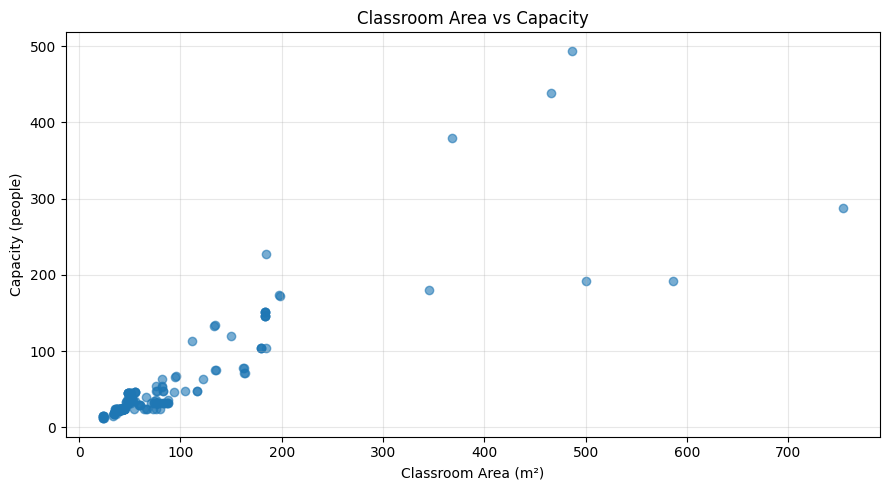

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.scatter(
    df_clean['area_m2'],
    df_clean['capacity'],
    alpha=0.6
)

plt.xlabel('Classroom Area (m²)')
plt.ylabel('Capacity (people)')
plt.title('Classroom Area vs Capacity')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
df_clean['area_per_seat_m2'] = (
    df_clean['area_m2'] / df_clean['capacity']
)

df_clean[
    ['bl_name', 'rm_id', 'capacity', 'area_m2', 'area_per_seat_m2']
].sort_values(
    by='area_per_seat_m2',
    ascending=False
).head(10).round(2)

,bl_name,rm_id,capacity,area_m2,area_per_seat_m2
191,Computer Design Research and Learning Center,2405,24,79.53,3.31
81,Burnham Hall,304,24,75.40,3.14
21,Grant Hall,204,24,73.34,3.06
179,Academic & Residential Complex,241,192,585.68,3.05
181,Computer Design Research and Learning Center,1402A,24,66.61,2.78
177,Academic & Residential Complex,239,32,87.53,2.74
182,Computer Design Research and Learning Center,1402B,24,65.59,2.73
174,Academic & Residential Complex,135,32,87.20,2.73
86,Burnham Hall,B10,32,86.42,2.70
193,Computer Design Research and Learning Center,2406B,32,85.66,2.68


In [17]:
furniture_summary = (
    df_clean.groupby('furniture_style', dropna=False)['area_per_seat_m2']
    .agg(['count', 'median', 'min', 'max'])
    .round(2)
    .sort_values(by='median', ascending=False)
)

furniture_summary

,count,median,min,max
furniture_style,,,,
NaN,15,2.50,1.92,3.31
Fixed Tables and Movable Chairs,24,1.87,1.25,3.05
Movable Tables and Movable Chairs,55,1.84,1.39,3.14
Movable Tablet Arm Chairs,69,1.72,1.32,2.02
Fixed Tables and Fixed Chairs,8,1.32,1.26,1.59
Fixed Tablet Arm Chairs,33,1.12,0.81,1.44


In [18]:
furniture_av_table = pd.crosstab(
    df_clean['furniture_style'].fillna('Unknown'),
    df_clean['multimedia_type'].fillna('Unknown')
)

furniture_av_table

multimedia_type,Flat panel,Integrated Multimedia Lectern,Integrated Multimedia Lectern(Enhanced),Plug and Play,Plug and Play(Enhanced),Simple,Unknown
furniture_style,,,,,,,
Fixed Tables and Fixed Chairs,0,0,8,0,0,0,0
Fixed Tables and Movable Chairs,0,5,19,0,0,0,0
Fixed Tablet Arm Chairs,0,5,28,0,0,0,0
Movable Tables and Movable Chairs,0,19,36,0,0,0,0
Movable Tablet Arm Chairs,28,0,23,1,13,4,0
Unknown,0,0,0,0,0,0,15


In [19]:
furniture_av_percent = pd.crosstab(
    df_clean['furniture_style'].fillna('Unknown'),
    df_clean['multimedia_type'].fillna('Unknown'),
    normalize='index'
).mul(100).round(1)

furniture_av_percent

multimedia_type,Flat panel,Integrated Multimedia Lectern,Integrated Multimedia Lectern(Enhanced),Plug and Play,Plug and Play(Enhanced),Simple,Unknown
furniture_style,,,,,,,
Fixed Tables and Fixed Chairs,0.0,0.0,100.0,0.0,0.0,0.0,0.0
Fixed Tables and Movable Chairs,0.0,20.8,79.2,0.0,0.0,0.0,0.0
Fixed Tablet Arm Chairs,0.0,15.2,84.8,0.0,0.0,0.0,0.0
Movable Tables and Movable Chairs,0.0,34.5,65.5,0.0,0.0,0.0,0.0
Movable Tablet Arm Chairs,40.6,0.0,33.3,1.4,18.8,5.8,0.0
Unknown,0.0,0.0,0.0,0.0,0.0,0.0,100.0


In [20]:
furniture_av_percent = pd.crosstab(
    df_clean['furniture_style'].fillna('Unknown'),
    df_clean['multimedia_type'].fillna('Unknown'),
    normalize='index'
).mul(100).round(1)

furniture_av_percent

multimedia_type,Flat panel,Integrated Multimedia Lectern,Integrated Multimedia Lectern(Enhanced),Plug and Play,Plug and Play(Enhanced),Simple,Unknown
furniture_style,,,,,,,
Fixed Tables and Fixed Chairs,0.0,0.0,100.0,0.0,0.0,0.0,0.0
Fixed Tables and Movable Chairs,0.0,20.8,79.2,0.0,0.0,0.0,0.0
Fixed Tablet Arm Chairs,0.0,15.2,84.8,0.0,0.0,0.0,0.0
Movable Tables and Movable Chairs,0.0,34.5,65.5,0.0,0.0,0.0,0.0
Movable Tablet Arm Chairs,40.6,0.0,33.3,1.4,18.8,5.8,0.0
Unknown,0.0,0.0,0.0,0.0,0.0,0.0,100.0


In [23]:
df_clean['capacity_group'] = pd.cut(
    df_clean['capacity'],
    bins=[0, 25, 50, 100, 200, float('inf')],
    labels=['1–25', '26–50', '51–100', '101–200', '201+']
)

capacity_av_count = pd.crosstab(
    df_clean['capacity_group'],
    df_clean['multimedia_type'].fillna('Unknown')
)

capacity_av_count

multimedia_type,Flat panel,Integrated Multimedia Lectern,Integrated Multimedia Lectern(Enhanced),Plug and Play,Plug and Play(Enhanced),Simple,Unknown
capacity_group,,,,,,,
1–25,28,10,32,1,13,4,3
26–50,0,12,51,0,0,0,11
51–100,0,1,12,0,0,0,0
101–200,0,6,14,0,0,0,1
201+,0,0,5,0,0,0,0


In [25]:
capacity_av_percent = pd.crosstab(
    df_clean['capacity_group'],
    df_clean['multimedia_type'].fillna('Unknown'),
    normalize='index'
).mul(100).round(1)

capacity_av_percent

multimedia_type,Flat panel,Integrated Multimedia Lectern,Integrated Multimedia Lectern(Enhanced),Plug and Play,Plug and Play(Enhanced),Simple,Unknown
capacity_group,,,,,,,
1–25,30.8,11.0,35.2,1.1,14.3,4.4,3.3
26–50,0.0,16.2,68.9,0.0,0.0,0.0,14.9
51–100,0.0,7.7,92.3,0.0,0.0,0.0,0.0
101–200,0.0,28.6,66.7,0.0,0.0,0.0,4.8
201+,0.0,0.0,100.0,0.0,0.0,0.0,0.0


In [26]:
df_clean['area_group'] = pd.cut(
    df_clean['area_m2'],
    bins=[0, 50, 100, 200, 400, float('inf')],
    labels=['≤50', '>50–100', '>100–200', '>200–400', '>400']
)

area_av_count = pd.crosstab(
    df_clean['area_group'],
    df_clean['multimedia_type'].fillna('Unknown')
)

area_av_count

multimedia_type,Flat panel,Integrated Multimedia Lectern,Integrated Multimedia Lectern(Enhanced),Plug and Play,Plug and Play(Enhanced),Simple,Unknown
area_group,,,,,,,
≤50,28,9,46,1,13,4,0
>50–100,0,13,40,0,0,0,14
>100–200,0,7,22,0,0,0,0
>200–400,0,0,1,0,0,0,1
>400,0,0,5,0,0,0,0


In [27]:
area_av_percent = pd.crosstab(
    df_clean['area_group'],
    df_clean['multimedia_type'].fillna('Unknown'),
    normalize='index'
).mul(100).round(1)

area_av_percent

multimedia_type,Flat panel,Integrated Multimedia Lectern,Integrated Multimedia Lectern(Enhanced),Plug and Play,Plug and Play(Enhanced),Simple,Unknown
area_group,,,,,,,
≤50,27.7,8.9,45.5,1.0,12.9,4.0,0.0
>50–100,0.0,19.4,59.7,0.0,0.0,0.0,20.9
>100–200,0.0,24.1,75.9,0.0,0.0,0.0,0.0
>200–400,0.0,0.0,50.0,0.0,0.0,0.0,50.0
>400,0.0,0.0,100.0,0.0,0.0,0.0,0.0


In [29]:
capacity_area_av = pd.crosstab(
    [df_clean['capacity_group'], df_clean['area_group']],
    df_clean['multimedia_type'].fillna('Unknown')
)

capacity_area_av

multimedia_type            Flat panel  Integrated Multimedia Lectern  \
capacity_group area_group                                              
1–25           ≤50                 28                              9   
               >50–100              0                              1   
26–50          ≤50                  0                              0   
               >50–100              0                             11   
               >100–200             0                              1   
51–100         >50–100              0                              1   
               >100–200             0                              0   
101–200        >100–200             0                              6   
               >200–400             0                              0   
               >400                 0                              0   
201+           >100–200             0                              0   
               >200–400             0                              0   
               >400                 0                              0   

multimedia_type            Integrated Multimedia Lectern(Enhanced)  \
capacity_group area_group                                            
1–25           ≤50                                              29   
               >50–100                                           3   
26–50          ≤50                                              17   
               >50–100                                          32   
               >100–200                                          2   
51–100         >50–100                                           5   
               >100–200                                          7   
101–200        >100–200                                         12   
               >200–400                                          0   
               >400                                              2   
201+           >100–200                                          1   
               >200–400                                          1   
               >400                                              3   

multimedia_type            Plug and Play  Plug and Play(Enhanced)  Simple  \
capacity_group area_group                                                   
1–25           ≤50                     1                       13       4   
               >50–100                 0                        0       0   
26–50          ≤50                     0                        0       0   
               >50–100                 0                        0       0   
               >100–200                0                        0       0   
51–100         >50–100                 0                        0       0   
               >100–200                0                        0       0   
101–200        >100–200                0                        0       0   
               >200–400                0                        0       0   
               >400                    0                        0       0   
201+           >100–200                0                        0       0   
               >200–400                0                        0       0   
               >400                    0                        0       0   

multimedia_type            Unknown  
capacity_group area_group           
1–25           ≤50               0  
               >50–100           3  
26–50          ≤50               0  
               >50–100          11  
               >100–200          0  
51–100         >50–100           0  
               >100–200          0  
101–200        >100–200          0  
               >200–400          1  
               >400              0  
201+           >100–200          0  
               >200–400          0  
               >400              0

In [30]:
capacity_area_av.reset_index()

multimedia_type,capacity_group,area_group,Flat panel,Integrated Multimedia Lectern,Integrated Multimedia Lectern(Enhanced),Plug and Play,Plug and Play(Enhanced),Simple,Unknown
0,1–25,≤50,28,9,29,1,13,4,0
1,1–25,>50–100,0,1,3,0,0,0,3
2,26–50,≤50,0,0,17,0,0,0,0
3,26–50,>50–100,0,11,32,0,0,0,11
4,26–50,>100–200,0,1,2,0,0,0,0
5,51–100,>50–100,0,1,5,0,0,0,0
6,51–100,>100–200,0,0,7,0,0,0,0
7,101–200,>100–200,0,6,12,0,0,0,0
8,101–200,>200–400,0,0,0,0,0,0,1
9,101–200,>400,0,0,2,0,0,0,0


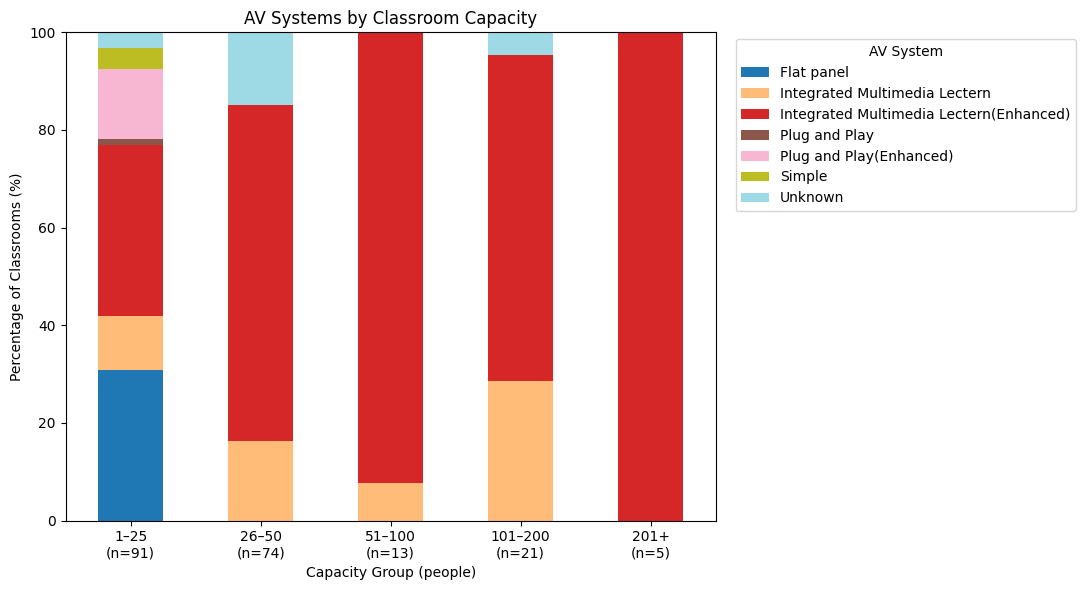

In [31]:
import matplotlib.pyplot as plt

ax = capacity_av_percent.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6),
    colormap='tab20'
)

ax.set_title('AV Systems by Classroom Capacity')
ax.set_xlabel('Capacity Group (people)')
ax.set_ylabel('Percentage of Classrooms (%)')
ax.set_ylim(0, 100)

group_counts = capacity_av_count.sum(axis=1)

ax.set_xticklabels(
    [f'{group}\n(n={group_counts.loc[group]})'
     for group in capacity_av_percent.index],
    rotation=0
)

ax.legend(
    title='AV System',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

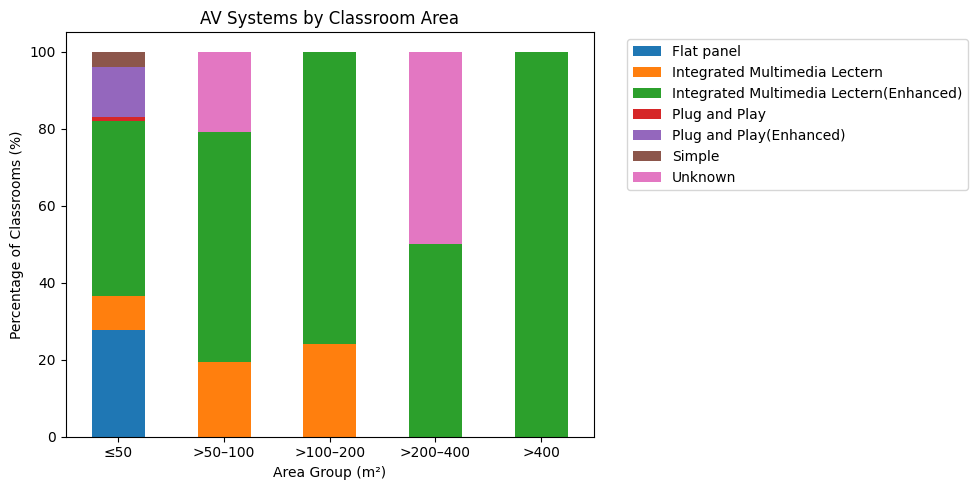

In [33]:
area_av_percent.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5)
)

plt.xlabel('Area Group (m²)')
plt.ylabel('Percentage of Classrooms (%)')
plt.title('AV Systems by Classroom Area')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

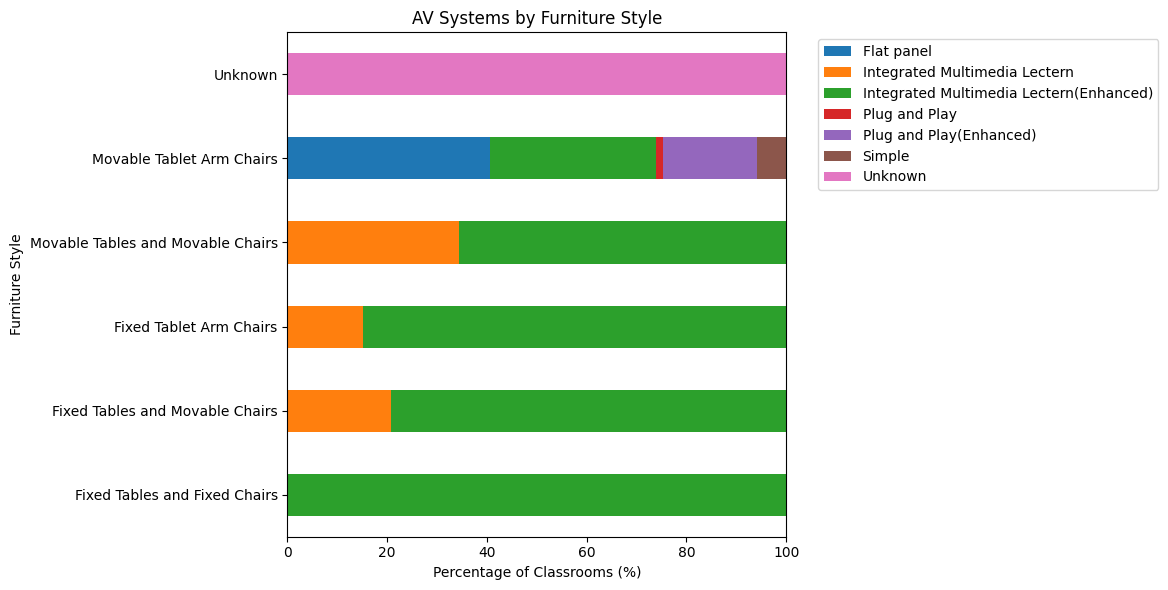

In [34]:
furniture_av_percent.plot(
    kind='barh',
    stacked=True,
    figsize=(12, 6)
)

plt.xlabel('Percentage of Classrooms (%)')
plt.ylabel('Furniture Style')
plt.title('AV Systems by Furniture Style')
plt.xlim(0, 100)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

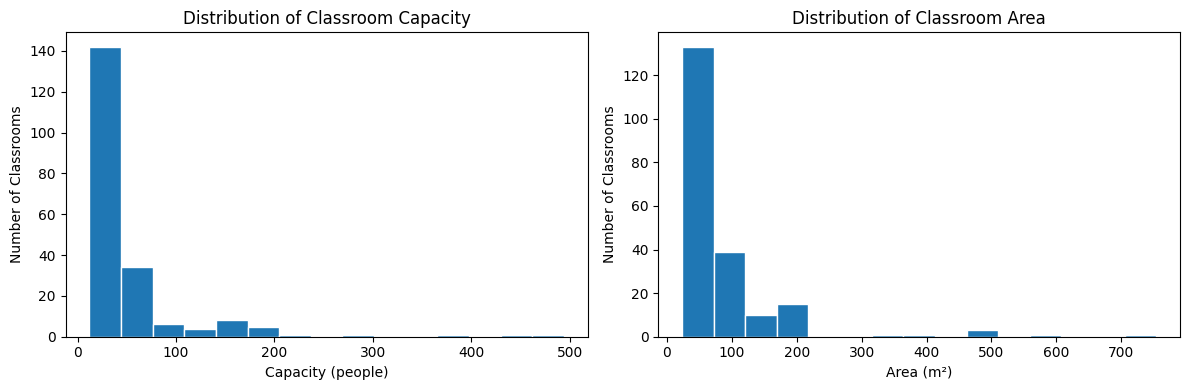

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_clean['capacity'], bins=15, edgecolor='white')
axes[0].set_title('Distribution of Classroom Capacity')
axes[0].set_xlabel('Capacity (people)')
axes[0].set_ylabel('Number of Classrooms')

axes[1].hist(df_clean['area_m2'], bins=15, edgecolor='white')
axes[1].set_title('Distribution of Classroom Area')
axes[1].set_xlabel('Area (m²)')
axes[1].set_ylabel('Number of Classrooms')

plt.tight_layout()
plt.show()

In [36]:
features = ['capacity', 'area_m2']

X = df_clean[features].copy()

print("Missing values:")
print(X.isnull().sum())

X.head()

Missing values:
capacity    0
area_m2     0
dtype: int64


,capacity,area_m2
0,380,367.757613
1,31,47.021016
2,31,47.877582
3,36,47.457660
4,36,48.021581


In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

X_scaled_df.head()

,capacity,area_m2
0,5.131871,3.076603
1,-0.321963,-0.382202
2,-0.321963,-0.372965
3,-0.243828,-0.377493
4,-0.243828,-0.371412


In [38]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        'k': k,
        'inertia': model.inertia_,
        'silhouette': silhouette_score(X_scaled, labels)
    })

k_results = pd.DataFrame(results)

k_results.round(3)

,k,inertia,silhouette
0,2,143.136,0.868
1,3,57.210,0.786
2,4,35.308,0.790
3,5,26.637,0.714
4,6,20.226,0.547


In [39]:
model_k2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# نسخة منفصلة لتجربة مجموعتين
rooms_k2 = df_clean.copy()
rooms_k2['cluster'] = model_k2.fit_predict(X_scaled)

summary_k2 = rooms_k2.groupby('cluster').agg(
    room_count=('capacity', 'size'),
    median_capacity=('capacity', 'median'),
    median_area_m2=('area_m2', 'median')
)

summary_k2.round(1)

,room_count,median_capacity,median_area_m2
cluster,,,
0,197,32.0,49.9
1,7,288.0,486.9


In [40]:
model_k3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rooms_k3 = df_clean.copy()
rooms_k3['cluster'] = model_k3.fit_predict(X_scaled)

summary_k3 = rooms_k3.groupby('cluster').agg(
    room_count=('capacity', 'size'),
    median_capacity=('capacity', 'median'),
    median_area_m2=('area_m2', 'median')
)

summary_k3.round(1)

,room_count,median_capacity,median_area_m2
cluster,,,
0,172,24.0,46.4
1,6,334.0,493.4
2,26,134.0,181.7


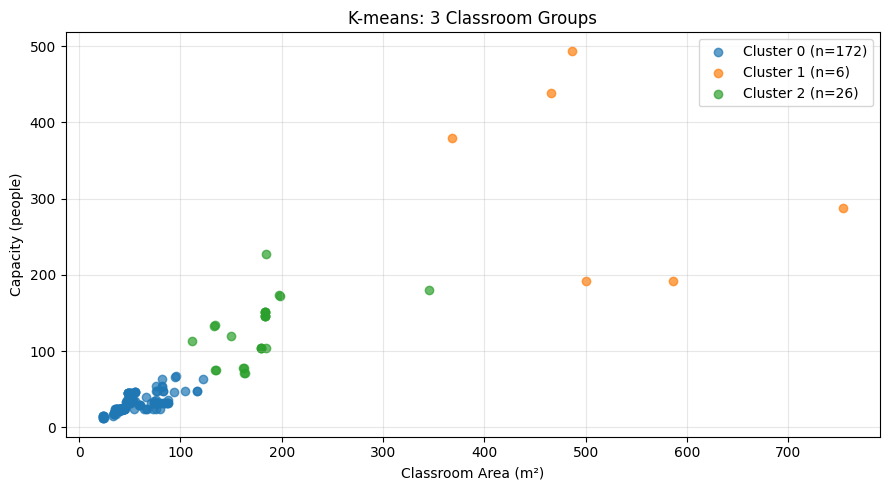

In [41]:
plt.figure(figsize=(9, 5))

for cluster_id, group in rooms_k3.groupby('cluster'):
    plt.scatter(
        group['area_m2'],
        group['capacity'],
        label=f'Cluster {cluster_id} (n={len(group)})',
        alpha=0.7
    )

plt.xlabel('Classroom Area (m²)')
plt.ylabel('Capacity (people)')
plt.title('K-means: 3 Classroom Groups')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
model_k4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rooms_k4 = df_clean.copy()
rooms_k4['cluster'] = model_k4.fit_predict(X_scaled)

summary_k4 = rooms_k4.groupby('cluster').agg(
    room_count=('capacity', 'size'),
    median_capacity=('capacity', 'median'),
    median_area_m2=('area_m2', 'median')
)

summary_k4.round(1)

,room_count,median_capacity,median_area_m2
cluster,,,
0,172,24.0,46.4
1,3,192.0,585.7
2,26,134.0,181.7
3,3,438.0,465.3


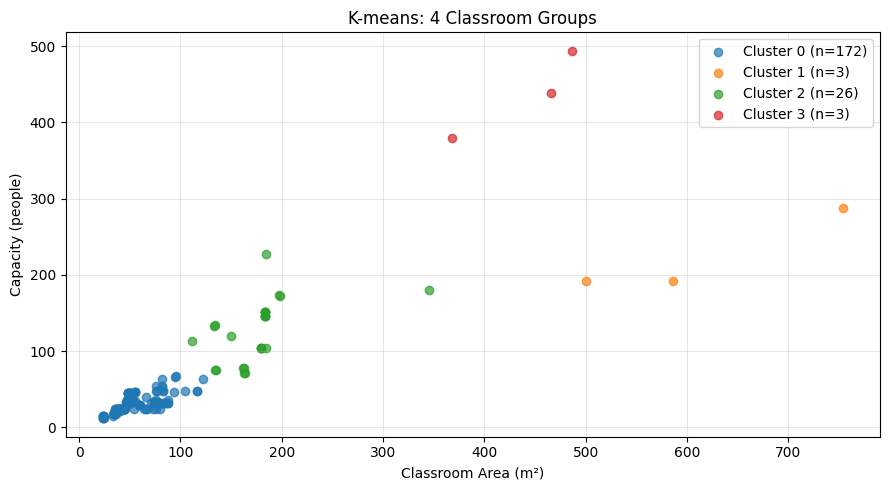

In [43]:
plt.figure(figsize=(9, 5))

for cluster_id, group in rooms_k4.groupby('cluster'):
    plt.scatter(
        group['area_m2'],
        group['capacity'],
        label=f'Cluster {cluster_id} (n={len(group)})',
        alpha=0.7
    )

plt.xlabel('Classroom Area (m²)')
plt.ylabel('Capacity (people)')
plt.title('K-means: 4 Classroom Groups')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
cluster_av_count = pd.crosstab(
    rooms_k4['cluster'],
    rooms_k4['multimedia_type'].fillna('Unknown')
)

cluster_av_count

multimedia_type,Flat panel,Integrated Multimedia Lectern,Integrated Multimedia Lectern(Enhanced),Plug and Play,Plug and Play(Enhanced),Simple,Unknown
cluster,,,,,,,
0,28,23,89,1,13,4,14
1,0,0,3,0,0,0,0
2,0,6,19,0,0,0,1
3,0,0,3,0,0,0,0


In [45]:
cluster_furniture_count = pd.crosstab(
    rooms_k4['cluster'],
    rooms_k4['furniture_style'].fillna('Unknown')
)

cluster_furniture_count

furniture_style,Fixed Tables and Fixed Chairs,Fixed Tables and Movable Chairs,Fixed Tablet Arm Chairs,Movable Tables and Movable Chairs,Movable Tablet Arm Chairs,Unknown
cluster,,,,,,
0,4,10,20,55,69,14
1,0,3,0,0,0,0
2,4,11,10,0,0,1
3,0,0,3,0,0,0


In [46]:
from sklearn.metrics import adjusted_rand_score

stability_results = []

for seed in [0, 10, 20, 30, 42]:
    test_model = KMeans(
        n_clusters=4,
        random_state=seed,
        n_init=10
    )

    test_labels = test_model.fit_predict(X_scaled)

    stability_results.append({
        'random_state': seed,
        'ARI': adjusted_rand_score(
            rooms_k4['cluster'],
            test_labels
        )
    })

pd.DataFrame(stability_results).round(3)

,random_state,ARI
0,0,1.0
1,10,1.0
2,20,1.0
3,30,1.0
4,42,1.0


# Classroom AV Assessment: Findings and Conclusions

## Objective
This exploratory study analysed 204 classrooms to examine how recorded AV system types vary with capacity, floor area, and furniture. K-means clustering was used to identify groups of rooms with similar capacity and area, supporting further review rather than prescribing AV designs.

## Data Preparation
No duplicate rows or duplicate room identities were found. Zero values in three room-dimension columns were treated as missing measurements. Original data were preserved in a separate DataFrame.

Four features were created: area in square metres, area per seat, capacity groups, and area groups. Missing AV system and furniture categories were displayed as “Unknown” rather than inferred.

## Key Findings
- AV system type was missing for 15 classrooms, all within the Computer Design Research and Learning Center. This represents 15 of the building’s 16 recorded classrooms (93.75%).
- All recorded Flat panel, Plug and Play, Enhanced Plug and Play, and Simple systems occurred in rooms accommodating no more than 24 people and measuring no more than 50 m². These are observed patterns, not design thresholds.
- Lectern systems appeared across a broader range of room sizes. Median capacity was similar for standard and enhanced lectern systems: 35 and 36 people respectively.
- Area generally increased with capacity, but rooms with similar capacities could have different areas.
- Median area per seat varied by furniture type, from 1.12 m² for fixed tablet-arm chairs to 1.87 m² for fixed tables with movable chairs. This association does not establish causation.

## Clustering Results
K-means used two inputs: capacity and area in square metres, standardised using StandardScaler. AV system type and furniture were excluded from training and used afterwards to interpret the groups.

Values of K from 2 to 6 were evaluated. K=2 achieved the highest silhouette score (0.868), but grouped 197 classrooms together and separated seven large rooms. K=4 was retained as an exploratory alternative because it revealed additional differences among the large rooms. Its silhouette score was 0.790.

| Cluster | Rooms | Median capacity | Median area (m²) |
|---|---:|---:|---:|
| 0 | 172 | 24 | 46.4 |
| 1 | 3 | 192 | 585.7 |
| 2 | 26 | 134 | 181.7 |
| 3 | 3 | 438 | 465.3 |

Cluster 0 contained all six known AV system categories. Cluster 2 contained 19 enhanced lectern systems, six standard lectern systems, and one unknown system.

Clusters 1 and 3 both contained only enhanced lectern systems. However, Cluster 1 contained fixed tables with movable chairs, while Cluster 3 contained fixed tablet-arm chairs. The split therefore revealed a spatial and furniture distinction without revealing a difference in the recorded AV system category.

The K=4 assignments were identical across five tested random seeds, with ARI=1.0 against the reference partition. This demonstrates stability to those initialisations, not predictive accuracy or engineering validity.

## Practical Implications and Limitations
The analysis provides a targeted list for completing missing records and groups of classrooms for comparative review. It can support discussions about standardisation, but does not establish that differing systems require replacement.

The study covers one institution and uses broad system categories. Two clusters contain only three rooms each, while the largest cluster remains diverse. Missing data are concentrated in one building. Stability under alternative samples, feature choices, or preprocessing was not tested.

Final AV design decisions require room layouts, viewing distances, acoustic conditions, equipment details, and user requirements. The findings support assessment and further investigation; they do not determine screen sizes, loudspeaker quantities, or suitable equipment.